<a id="sprint2_description"></a>
# Lab01 — sprint 2

## Random 01 — массовая доля Na₂O в глазури


## Структура исследования

1. [Описание](#s2description)
2. [Математическая справка](#s2math)
3. [Код](#s2code)
4. [Тесты](#s2tests)
5. [Сравнение с реальными данными](#s2compare)
5. [Выводы](#s2resume)

<a id="s2description"></a>

### Описание

Генерируем **одно** положительное значение массовой доли Na₂O (масс. %) для нового условного образца глазури. В первом спринте из 44 наблюдений получены оценки параметров гамма-модели с фиксированным сдвигом `loc=0`: $k\approx1{,}431$, $\theta\approx0{,}3815$. Параметры ниже вычисляются заново из csv-файла

<a id="s2math"></a>
### Математическая справка

Для $X\sim\Gamma(k,\theta)$ плотность и первые два момента равны

$$
f_X(x)=\frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\theta^k},\quad x>0;\qquad
\operatorname E X=k\theta,\quad \operatorname{Var}X=k\theta^2.
$$

Здесь $k$ безразмерен, $\theta$ измеряется в масс. %, дисперсия — в $(\text{масс. }\%)^2$. Сначала получаем $Y\sim\Gamma(k,1)$, затем $X=\theta Y$. Оценку $k,\theta$ берём из `scipy.stats.gamma.fit(..., floc=0)`; именно такой способ применён в первом спринте.

Используем **метод принятия и отклонения Марсальи — Цанга**. При $k\ge1$ положим

$$d=k-\frac13,\qquad c=\frac1{\sqrt{9d}},\qquad
v=(1+cZ)^3,\qquad Z\sim N(0,1).$$

Если $1+cZ\le0$, кандидат отклоняем. Иначе берём независимое $U\sim U(0,1)$ и принимаем $Y=dv$, когда

$$\ln U<\frac{Z^2}{2}+d(1-v+\ln v).$$

Почему критерий работает: после замены $y=d(1+cz)^3$ плотность гамма-величины в координате $z$ пропорциональна $\exp\{d\ln v-dv+d\}$. Стандартная нормальная плотность пропорциональна $\exp(-z^2/2)$ и доминирует эту функцию при $k\ge1$. Поэтому отношение плотностей даёт указанную вероятность принятия. Константа нормировки сокращается. В коде используется полный логарифмический критерий без ускоряющей предварительной проверки (`squeeze`), чтобы логика оставалась видимой.

Нормальный кандидат тоже получаем из равномерных чисел преобразованием Бокса — Мюллера:

$$Z=\sqrt{-2\ln U_1}\cos(2\pi U_2),\qquad U_1,U_2\stackrel{ind}{\sim}U(0,1).$$

Для $0<k<1$ используем переход $Y=Y_{k+1}U^{1/k}$, где $Y_{k+1}\sim\Gamma(k+1,1)$ и $U$ независима. Действительно, условная плотность $Y\mid Y_{k+1}=t$ равна $k y^{k-1}/t^k$ на $(0,t)$. Интегрируя по $t$ с гамма-плотностью формы $k+1$, получаем $y^{k-1}e^{-y}/\Gamma(k)$.

**Литература**:
- [Кнут, *Искусство программирования*, т. 2, §3.4.1, локальный PDF](D_Knut_-_Iskusstvo_Programmirovania_tom_2.pdf) (обратное преобразование, нормальные и гамма-величины, PDF-страницы 150–151);

- [Марсалья и Цанг, *A Simple Method for Generating Gamma Variables*, ACM TOMS 26(3), 2000, с. 363–372](https://doi.org/10.1145/358407.358414), §2–3 и примечание на с. 371 (точный критерий и случай $k<1$);

- [Лагутин, *Наглядная математическая статистика*, §1–2, локальный PDF](lagutin_naglyadnaya_matematicheskaya_statistika.pdf) (плотность, математическое ожидание и дисперсия, с. 9–11).

Строк в CSV: 88. Полных пар: 44. Пропусков в этих четырёх столбцах нет.
Логнормальная модель: p = 0.0137
Гамма-модель: k = 1.4310, θ = 0.3815
D = 0.0754, p = 0.7605


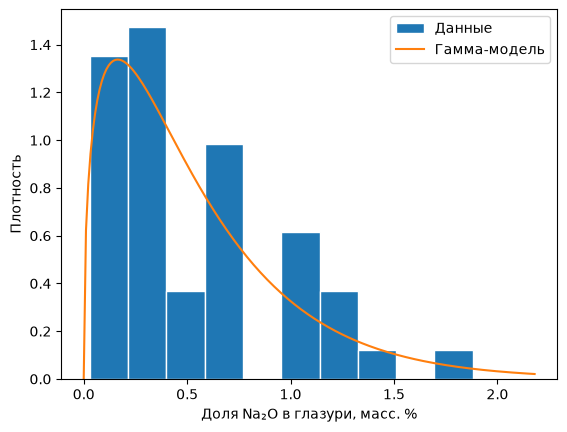

n = 44; k = 1.430976; θ = 0.381494 масс. %
Теория: E[X] = 0.5459 масс. %; Var[X] = 0.2083 (масс. %)^2
Получено 50,000 значений из 51,543 кандидатов; доля принятых = 97.006%
Первые десять значений, масс. %: [0.183 0.761 1.081 1.322 0.48  0.7   0.265 0.266 0.275 0.399]


,k,θ,|ошибка среднего| / SE,Отн. ошибка дисперсии,KS D,KS p,r соседних
0,0.600,0.8000,0.8194,0.0057,0.0059,0.1220,0.0028
1,1.000,0.8000,0.0163,0.0058,0.0034,0.7309,0.0000
2,1.431,0.3815,0.2864,0.0081,0.0027,0.9370,0.0033
3,4.000,0.8000,0.2949,0.0019,0.0031,0.8326,0.0047


Все автопроверки пройдены.


,CSV (n=44),Генератор (n=50 000),Нижняя граница 95%,Верхняя граница 95%,CSV внутри?
Метрика,,,,,
"Среднее, масс. %",0.5459,0.5414,0.4204,0.6942,да
"Дисперсия, (масс. %)^2",0.1901,0.2056,0.0955,0.4008,да
"Медиана, масс. %",0.3750,0.4218,0.2975,0.5887,да
"Q10, масс. %",0.1400,0.0983,0.0522,0.1909,да
"Q90, масс. %",1.1390,1.1379,0.7975,1.5191,да


KS для генератора против заданной Gamma(k, θ): D=0.0053, p=0.1144


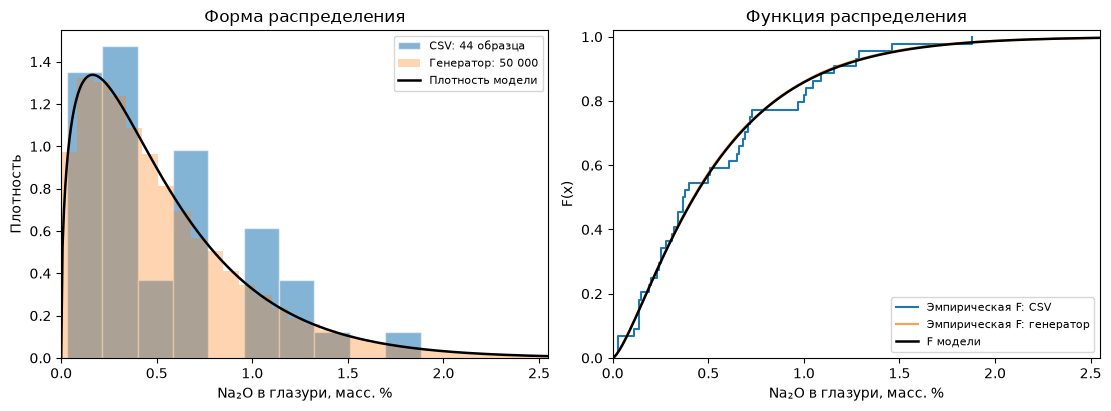

In [20]:
%run ./pylib.py

In [25]:
k_hat, loc_hat, theta_hat = fit_gamma_distribution(data, 'Na₂O в глазури')


<a id="s2code"></a>
### Код

`rng` — независимый поток `numpy.random.Generator`. Для воспроизводимости передаём фиксированный seed снаружи. Библиотечные `rng.gamma` и `scipy.stats.gamma.rvs` в реализации не используются. `1-rng.random(...)` гарантирует положительный аргумент логарифма даже если равномерный источник вернёт ноль.

In [22]:
generated, proposals = gamma_marsaglia_tsang(k_hat, theta_hat, 50_000, np.random.default_rng(20261111), diagnostics=True)

<a id="s2tests"></a>
### Тесты

Сначала проверяем воспроизводимость, область значений и некорректные аргументы. Затем для форм $k<1$, $k=1$ и $k>1$ сопоставляем выборочные моменты и функцию распределения с заранее заданной гамма-моделью.

In [23]:
a = gamma_marsaglia_tsang(k_hat, theta_hat, 1000, np.random.default_rng(seed))
b = gamma_marsaglia_tsang(k_hat, theta_hat, 1000, np.random.default_rng(seed))


<a id="s2compare"></a>
### Сравнение с реальными данными

Сравним 50 000 значений с теоретической гамма-функцией распределения при фиксированных параметрах. Для сравнения с исходными данными построим 5000 новых наборов по 44 значения и 95%-е модельные интервалы для статистик. Это интервалы вариации выборки при уже подогнанной модели. В первом спринте параметрический бутстрэп с повторной подгонкой дал $p=0{,}7605$ для гамма-модели.

In [24]:
ks_generator = stats.kstest(generated, 'gamma', args=(k_hat, 0, theta_hat))

<a id="s2resume"></a>
### Выводы

На 44 значениях оценены $k=1{,}4310$ и $\theta=0{,}3815$ масс. %. Основной генератор принял 50 000 значений из 51 543 кандидатов (97,0%). Его выборочные среднее $0{,}5414$ масс. % и дисперсия $0{,}2056$ $(\text{масс. }\%)^2$ близки к теоретическим $0{,}5459$ и $0{,}2083$; KS против заданной модели дал $D=0{,}0053$, $p=0{,}1144$. Все пять метрик CSV вошли в 95%-е модельные интервалы для выборок по 44 значения. Реализация переводит равномерные псевдослучайные числа в гамма-величину через нормальный кандидат и принятие/отклонение. Она корректно обрабатывает как найденный $k>1$, так и случай $0<k<1$. Автотесты проверяют поддержку, воспроизводимость, моменты, форму распределения и слабую сериальную связь. Альтернативное численное обращение $F$ даёт независимый способ получить тот же закон.

Сравнение с 44 реальными значениями относится к условной подогнанной модели. Оценка параметров и проверка сделаны на одном небольшом, заранее отобранном наборе. Кроме того, положительная гамма-модель формально не ограничена сверху 100 масс. %, хотя при найденных параметрах такая область практически недостижима. Генератор следует использовать для моделирования одной доли Na₂O в диапазоне и контексте этого набора, а не для воссоздания полного состава керамики.

## Lab resume

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|:--|:--|:--:|:--|
| Description | (#s2description) | - | |
|  Math Desc  | (#s2math) | - | |
|    Code     | (#s2code) | - |
|    Tests    | (#s2tests) | - |
|   Compare   | (#s2compare) | - |
|   Resume    | (#s2resume) | - |
